# Electrodynamics from Scratch — Lecture 4: Gradient Exercises

The electrostatic field and the scalar potential are two views of the same physics, tied together by the gradient. Given a potential $V(\mathbf{r})$, the field is

$$\mathbf{E} = -\nabla V = -\left(\frac{\partial V}{\partial x}\,\hat{x} + \frac{\partial V}{\partial y}\,\hat{y} + \frac{\partial V}{\partial z}\,\hat{z}\right).$$

The minus sign carries the physics: a charge accelerates *downhill* in potential, so $\mathbf{E}$ points in the direction of steepest *decrease* of $V$. For a point charge, $V = q/(4\pi\varepsilon_0\,r)$, and taking the gradient gives back Coulomb's law, $\mathbf{E} = q\,\hat{r}/(4\pi\varepsilon_0\,r^2)$.

The gradient also has a sharp geometric meaning. The **directional derivative** of $V$ along a unit vector $\hat{n}$ is $\partial V/\partial n = \hat{n}\cdot\nabla V$, and since $\mathbf{E} = -\nabla V$, the field component along $\hat{n}$ is $\mathbf{E}\cdot\hat{n} = -\partial V/\partial n$. Because $\hat{n}\cdot\nabla V$ vanishes for every $\hat{n}$ tangent to a level surface, $\nabla V$ — and hence $\mathbf{E}$ — is always **perpendicular to the equipotential surfaces** $V = \text{const}$. Field lines therefore cross equipotentials at right angles, which is exactly the classic textbook figure we draw below.

Taking one more derivative gives the **Laplacian**, $\nabla^2 V = \partial^2 V/\partial x^2 + \partial^2 V/\partial y^2 + \partial^2 V/\partial z^2$, and Gauss's law becomes Poisson's equation, $\nabla^2 V = -\rho/\varepsilon_0$. In charge-free regions the potential obeys **Laplace's equation**, $\nabla^2 V = 0$; indeed $\nabla^2(1/r) = 0$ for every $r \neq 0$, with the whole source concentrated in the singularity at the origin. One caution that the numerics will make vivid: on a single plane through the charge the *two-dimensional* Laplacian of $1/r$ is $1/r^3$, not zero — only the full three-dimensional Laplacian vanishes. We verify all of these statements with the `electrodynamics_from_scratch` package, using $q = 1\,\text{nC}$ so that $kq/r$ with $k = 1/(4\pi\varepsilon_0)$ stays a readable number of volts.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import electrodynamics_from_scratch as eds

# A 1 nC charge keeps k q / r in readable volts, with k = 1/(4 pi eps0)
q = 1e-9
kq = eds.K_COULOMB * q

## Worked example 1 — Field lines and equipotentials of a dipole

A dipole is two opposite charges held a fixed distance apart. We draw its field lines (streamlines of $\mathbf{E}$, colored by $\log_{10}|\mathbf{E}|$) over its equipotential contours: the lines cross the contours at right angles, exactly as $\mathbf{E} = -\nabla V$ demands. The numeric check at the end of the cell confirms that $\mathbf{E}$ and $\nabla V$ are anti-parallel everywhere on the grid.

mean of E . grad V / (|E| |grad V|) : -0.9999893080148805


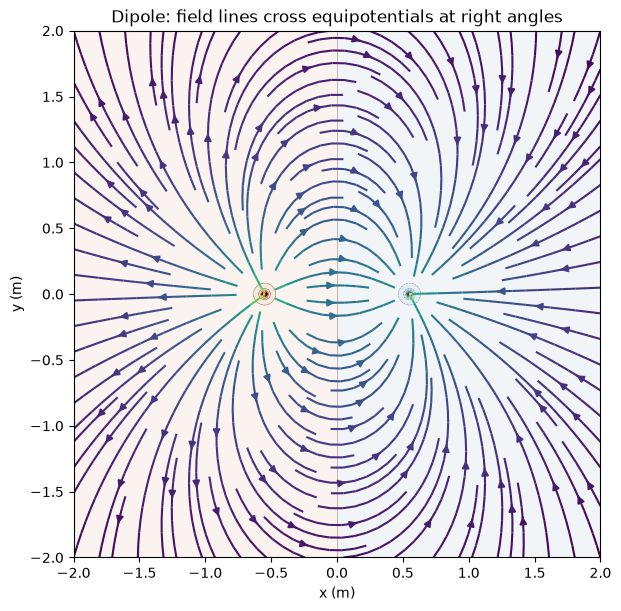

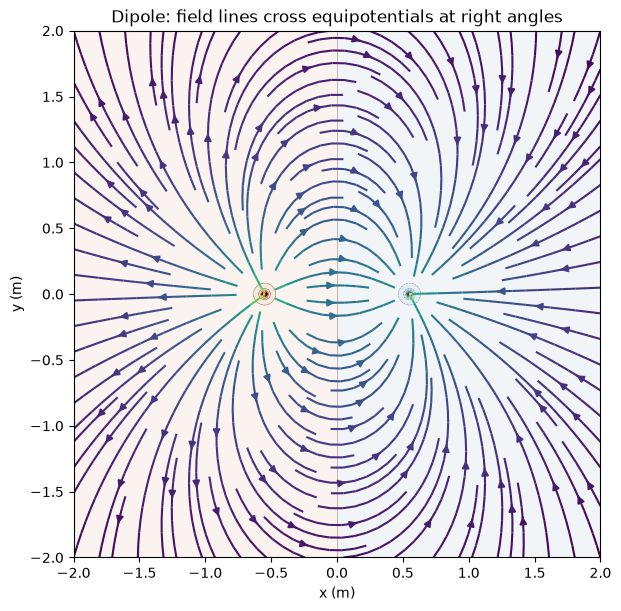

In [2]:
CHARGES = [(-q, np.array([ 0.55, 0.0, 0.0])),
           ( q, np.array([-0.55, 0.0, 0.0]))]

def dipole_field_func(x, y):
    """E components on a meshgrid (rows = y, columns = x), z = 0 plane."""
    pts = np.column_stack([x.ravel(), y.ravel(), np.zeros(x.size)])
    E, _ = eds.superpose(charges=CHARGES, points=pts)
    return E[:, 0].reshape(x.shape), E[:, 1].reshape(x.shape)

def dipole_potential_func(x, y):
    pts = np.column_stack([x.ravel(), y.ravel(), np.zeros(x.size)])
    _, V = eds.superpose(charges=CHARGES, points=pts)
    return V.reshape(x.shape)

fig, ax = eds.plot_field_and_potential(dipole_field_func, dipole_potential_func,
                                       extent=2.0, density=1.4, levels=20,
                                       title='Dipole: field lines cross equipotentials at right angles')

# E = -grad V, so E and grad V must be anti-parallel (cosine of the angle = -1)
axis = np.linspace(-2.0, 2.0, 201)
x, y = np.meshgrid(axis, axis)
Ex, Ey = dipole_field_func(x, y)
V_dip = dipole_potential_func(x, y)
dV_dy, dV_dx = np.gradient(V_dip, axis[1] - axis[0])   # axis order: y first, then x
cos_angle = (Ex*dV_dx + Ey*dV_dy) / np.sqrt((Ex**2 + Ey**2) * (dV_dx**2 + dV_dy**2))
good = np.sqrt((Ex**2 + Ey**2) * (dV_dx**2 + dV_dy**2)) > 1e-9
print('mean of E . grad V / (|E| |grad V|) :', np.mean(cos_angle[good]))
fig

## Worked example 2 — The gradient of $1/r$ on a grid

We sample the potential $V = kq/r$ of a single $1\,\text{nC}$ charge on a grid and let `eds.electric_field_from_potential` differentiate it: $\mathbf{E} = -\nabla V$. The result matches the analytic Coulomb field $\mathbf{E} = kq\,\hat{r}/r^2$ to a small fraction of a percent in the interior of the grid, and the error map shows the expected pattern: finite differences lose accuracy where $V$ curves most sharply, i.e. close to the charge and at the grid boundaries.

max |E_numeric - E_exact| in the annulus : 0.011662114769901843 V/m
|E| at r = 0.5 m                         : 35.95020716904469 V/m
max relative error                       : 0.00032439631613426787


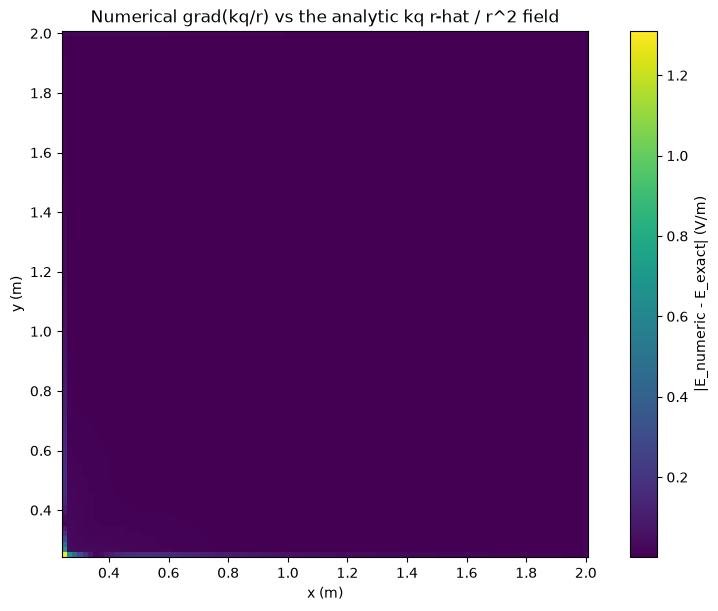

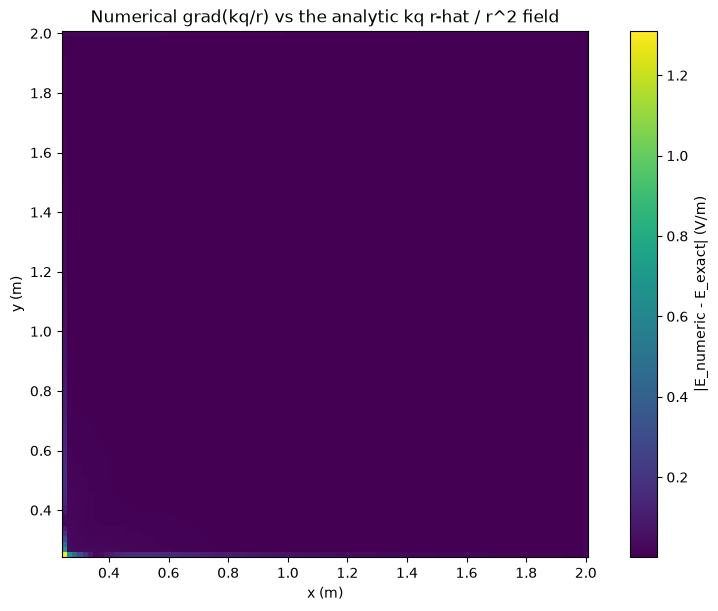

In [3]:
x = np.linspace(0.25, 2.0, 100)
dx = x[1] - x[0]
X, Y = np.meshgrid(x, x)              # rows = y, columns = x
R = np.sqrt(X**2 + Y**2)
V_grid = kq / R                       # potential of the 1 nC charge at the origin

# The eds grid helpers return derivatives along the array axes in order:
# axis 0 (= y) first, axis 1 (= x) second for a meshgrid-built grid.
Ey_num, Ex_num = eds.electric_field_from_potential(V_grid, dx)

Ex_exact = kq * X / R**3              # E = kq r-hat / r^2
Ey_exact = kq * Y / R**3
err = np.sqrt((Ex_num - Ex_exact)**2 + (Ey_num - Ey_exact)**2)

interior = np.zeros_like(R, dtype=bool)
interior[5:-5, 5:-5] = True           # drop the one-sided boundary rows
annulus = interior & (R > 0.5) & (R < 1.9)
print('max |E_numeric - E_exact| in the annulus :', np.max(err[annulus]), 'V/m')
print('|E| at r = 0.5 m                         :', kq / 0.5**2, 'V/m')
print('max relative error                       :', np.max(err[annulus]) / (kq / 0.5**2))

fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
pc = ax.pcolormesh(X, Y, err, cmap='viridis', shading='auto')
fig.colorbar(pc, ax=ax, label='|E_numeric - E_exact| (V/m)')
ax.set_aspect('equal')
ax.set_xlabel('x (m)')
ax.set_ylabel('y (m)')
ax.set_title('Numerical grad(kq/r) vs the analytic kq r-hat / r^2 field')
fig

## Worked example 3 — A directional derivative

The rate of change of $V$ along a unit vector $\hat{n}$ is $\partial V/\partial n = \hat{n}\cdot\nabla V$. We assemble it on the grid with `np.gradient` along $\hat{n} = (3, 4, 0)/5$ and check it against the analytic value $-kq\,(\hat{n}\cdot\hat{r})/r^2$. Since $\mathbf{E} = -\nabla V$, the field component along $\hat{n}$ follows immediately: $\mathbf{E}\cdot\hat{n} = -\partial V/\partial n$.

max |numeric - analytic| dV/dn in the annulus : 0.01119053867474662 V/m
max |E . n-hat + dV/dn| in the annulus        : 0.0 V/m


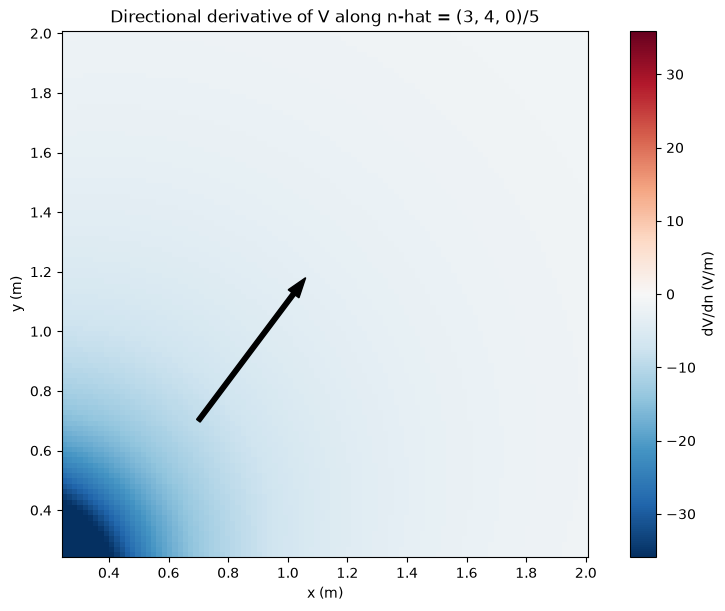

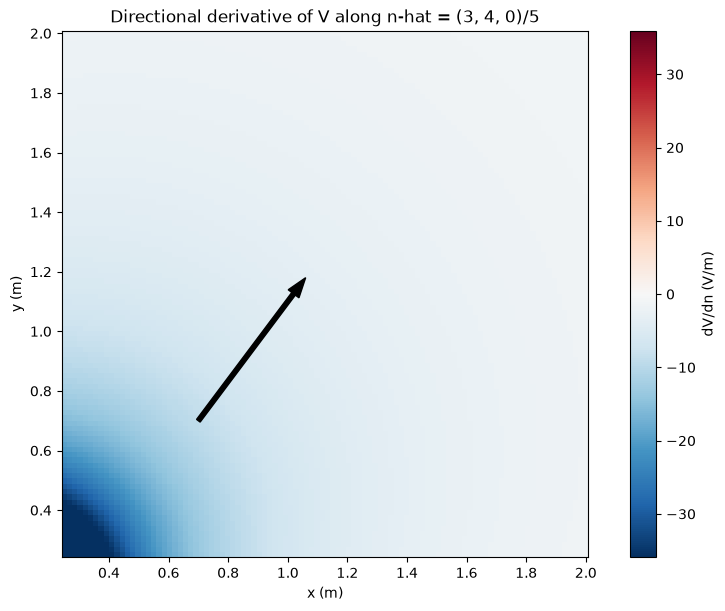

In [4]:
n_hat = np.array([3.0, 4.0, 0.0]) / 5.0    # a unit vector in the plane

dV_dy, dV_dx = np.gradient(V_grid, dx)     # axis order: y first, then x
dV_dn = n_hat[0]*dV_dx + n_hat[1]*dV_dy                    # numeric n-hat . grad V
dV_dn_exact = -kq * (n_hat[0]*X + n_hat[1]*Y) / R**3       # analytic

print('max |numeric - analytic| dV/dn in the annulus :',
      np.max(np.abs(dV_dn - dV_dn_exact)[annulus]), 'V/m')
print('max |E . n-hat + dV/dn| in the annulus        :',
      np.max(np.abs((Ex_num*n_hat[0] + Ey_num*n_hat[1]) + dV_dn)[annulus]), 'V/m')

fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
pc = ax.pcolormesh(X, Y, dV_dn, cmap='RdBu_r', shading='auto',
                   vmin=-kq / 0.5**2, vmax=kq / 0.5**2)
ax.arrow(0.7, 0.7, 0.6*n_hat[0], 0.6*n_hat[1], width=0.015,
         color='black', length_includes_head=True)
fig.colorbar(pc, ax=ax, label='dV/dn (V/m)')
ax.set_aspect('equal')
ax.set_xlabel('x (m)')
ax.set_ylabel('y (m)')
ax.set_title('Directional derivative of V along n-hat = (3, 4, 0)/5')
fig

## Worked example 4 — The Laplacian of $1/r$ and Laplace's equation

Gauss's law in potential form is $\nabla^2 V = -\rho/\varepsilon_0$, so away from the charge ($\rho = 0$) the potential must satisfy Laplace's equation $\nabla^2 V = 0$. We check this on a full three-dimensional grid. We also compute the Laplacian on the $z = 0$ plane alone: there the missing $\partial^2 V/\partial z^2$ term equals $-kq/r^3$, so the two-dimensional Laplacian comes out as $+kq/r^3$ — a reminder that $\nabla^2(1/r) = 0$ is a *three-dimensional* statement.

In [5]:
axis = np.linspace(-2.0, 2.0, 100)
dx3 = axis[1] - axis[0]
X3, Y3, Z3 = np.meshgrid(axis, axis, axis, indexing='ij')
R3 = np.sqrt(X3**2 + Y3**2 + Z3**2)
V3 = kq / R3

lap3 = eds.laplacian(V3, dx3)
interior3 = np.zeros_like(R3, dtype=bool)
interior3[5:-5, 5:-5, 5:-5] = True
shell = interior3 & (R3 > 0.9)
print('3D: max |lap V| for r > 0.9 m      :', np.max(np.abs(lap3[shell])), 'V/m^2')
print('3D: characteristic scale kq/r^3    :', kq / 0.9**3, 'V/m^2')

# On the z = 0 plane the 2D Laplacian is NOT zero: the missing z-derivative
# contributes -kq/r^3 there, so the 2D Laplacian equals +kq/r^3.
x2 = np.linspace(0.25, 2.0, 100)
dx2 = x2[1] - x2[0]
X2, Y2 = np.meshgrid(x2, x2)
R2 = np.sqrt(X2**2 + Y2**2)
lap2 = eds.laplacian(kq / R2, dx2)
inner2 = np.zeros_like(R2, dtype=bool)
inner2[5:-5, 5:-5] = True
ann2 = inner2 & (R2 > 0.5) & (R2 < 1.9)
print('2D plane: max |lap V - kq/r^3|     :',
      np.max(np.abs(lap2[ann2] - kq / R2[ann2]**3)), 'V/m^2')

3D: max |lap V| for r > 0.9 m      : 0.3289410132076753 V/m^2
3D: characteristic scale kq/r^3    : 12.328603281565393 V/m^2
2D plane: max |lap V - kq/r^3|     : 0.5648584143572606 V/m^2


## Worked example 5 — Laplace's equation for the dipole

The same statement holds for any charge-free region: superposing point charges cannot spoil Laplace's equation, because the Laplacian is linear and each $1/r$ term satisfies it away from its own source. We build the dipole potential of Worked example 1 on the same three-dimensional grid, take its Laplacian, and confirm that it vanishes everywhere except in the immediate neighbourhood of the two charges.

max |lap V| away from the charges    : 0.337445476353869 V/m^2
characteristic scale kq/r^3 at 0.9 m : 12.328603281565393 V/m^2


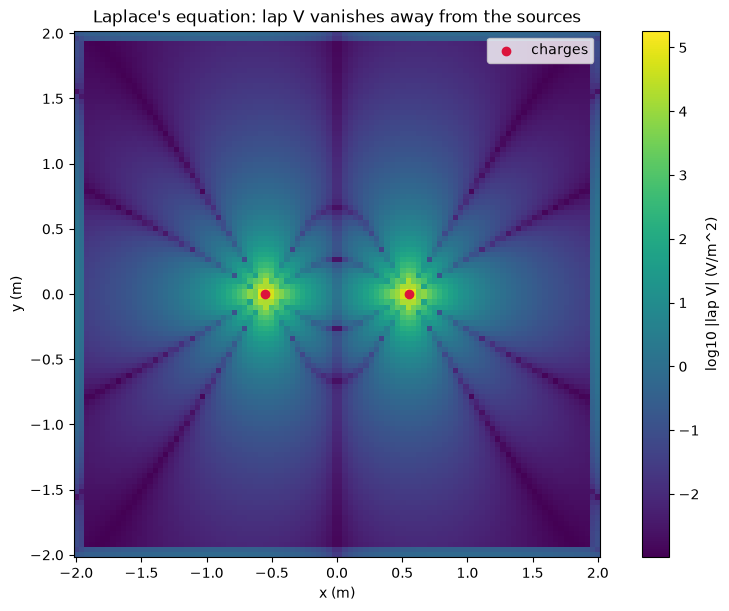

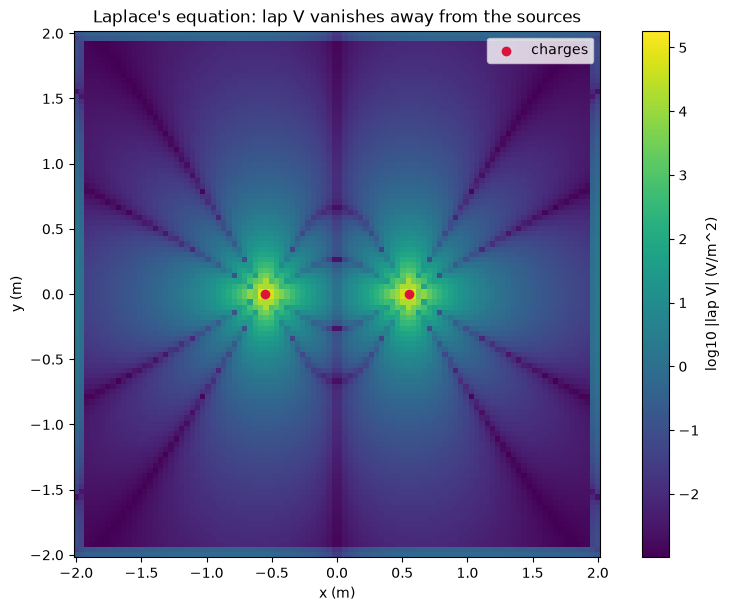

In [6]:
pts3 = np.column_stack([X3.ravel(), Y3.ravel(), Z3.ravel()])
_, V_dip3 = eds.superpose(charges=CHARGES, points=pts3)
V_dip3 = V_dip3.reshape(X3.shape)

lap_dip3 = eds.laplacian(V_dip3, dx3)
r_charges = np.minimum(np.sqrt((X3 - 0.55)**2 + Y3**2 + Z3**2),
                       np.sqrt((X3 + 0.55)**2 + Y3**2 + Z3**2))
away = interior3 & (r_charges > 0.9)
print('max |lap V| away from the charges    :', np.max(np.abs(lap_dip3[away])), 'V/m^2')
print('characteristic scale kq/r^3 at 0.9 m :', kq / 0.9**3, 'V/m^2')

# A slice near z = 0: the Laplacian is large only at the two charges
k0 = np.argmin(np.abs(axis))
fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
pc = ax.pcolormesh(X3[:, :, k0], Y3[:, :, k0],
                   np.log10(np.abs(lap_dip3[:, :, k0]) + 1e-3),
                   cmap='viridis', shading='auto')
ax.scatter([0.55, -0.55], [0.0, 0.0], color='crimson', marker='o', label='charges')
fig.colorbar(pc, ax=ax, label='log10 |lap V| (V/m^2)')
ax.set_aspect('equal')
ax.set_xlabel('x (m)')
ax.set_ylabel('y (m)')
ax.legend(loc='upper right')
ax.set_title("Laplace's equation: lap V vanishes away from the sources")
fig

## Exercises

1. **Conceptual.** The definition $\mathbf{E} = -\nabla V$ carries a minus sign. Explain in words why the field must point from high to low potential, and what would be unphysical about defining $\mathbf{E} = +\nabla V$ instead.
2. **Conceptual.** Use $\mathbf{E}\cdot d\mathbf{l} = -dV$ to explain why field lines must cross equipotential surfaces at right angles. Can two distinct equipotentials intersect each other? Can a field line meet an equipotential at an oblique angle?
3. **Coding.** Repeat Worked example 2 for the dipole: sample the dipole potential on a grid with `eds.superpose` (reuse `CHARGES`), differentiate it with `eds.electric_field_from_potential`, and compare against the field that `eds.superpose` returns directly at the same points. Where is the agreement worst, and why?
4. **Coding.** Turn Worked example 2 into a convergence study: for grids with 50, 100 and 200 points along each axis over the same annulus $0.5 < r < 1.9$, compute the maximum relative error of the numerical gradient of $kq/r$, and check that halving $dx$ shrinks it by roughly a factor of four (second-order accuracy). Keep the axis-order convention from Worked example 2 in mind.
5. **Coding.** Using `eds.gaussian_delta`, build a smeared charge density $\rho$ on a 2D grid and solve Poisson's equation $\nabla^2 V = -\rho/\varepsilon_0$ with `eds.poisson_solve`. Then verify with `eds.laplacian` that the returned $V$ satisfies the equation (use `eds.EPSILON_0`), checking in the interior of the grid and away from the smeared charge.